In [13]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False
import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier,KNeighborsRegressor
from sklearn.linear_model import LinearRegression,Ridge,Lasso,LogisticRegression 
from sklearn.metrics import mean_absolute_error   # 평균절대값오차 오차범위
from sklearn.preprocessing import PolynomialFeatures,StandardScaler  
from sklearn.model_selection import train_test_split
from scipy.special import expit, softmax    # expit:이진분류,softmax:다중분류 0-1 숫자로 변환
from sklearn.linear_model import SGDClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from sklearn.model_selection import cross_validate
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import GridSearchCV

In [14]:
# 데이터 가져오기
wine = pd.read_csv('data/wine.csv')
wine.head(2)
data = wine[wine.columns[:-1]].values
label = wine['class'].values
# 데이터 분리
train_data,test_data,train_label,test_label = \
train_test_split(data,label,test_size=0.2,random_state=42)

In [15]:
# 정규화작업
ss = StandardScaler()
ss.fit(train_data)
train_scaled = ss.transform(train_data)
test_scaled = ss.transform(test_data) 

In [16]:
lr = LogisticRegression()
# C규제, 반복횟수을 조정해서 훈련진행
params = {
    'C': [0.01, 0.1, 1, 10, 100],
    'max_iter': [100, 500, 1000]
}

gs = GridSearchCV(lr, params, cv=5,return_train_score=True)
gs.fit(train_data, train_label)
print(gs.best_params_)
print(gs.best_score_)

{'C': 10, 'max_iter': 100}
0.7814150070333901


In [22]:
train_score = gs.cv_results_['mean_train_score']
test_score = gs.cv_results_['mean_test_score']

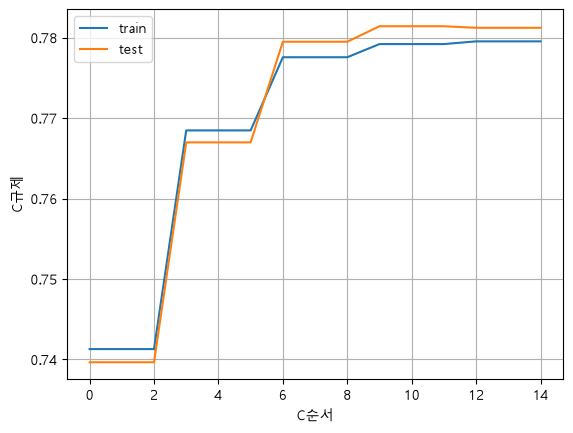

In [23]:
# C의 규제 선그래프
list1 = range(15)
plt.plot(list1,train_score)
plt.plot(list1,test_score)
plt.xlabel('C순서')
plt.ylabel('C규제')
plt.legend(['train','test'])
plt.grid()
plt.show()